
# IMAES - Experiment 2: Production Rules and the Match Phase

## Aim
To represent domain knowledge as IF–THEN production rules, hold facts in working memory (WM), and compute the conflict set of applicable rules.



# 1. Theory

A production system has three parts:
1. a **rule base** of IF–THEN productions;
2. **working memory (WM)** containing currently believed facts;
3. an inference engine running the recognise–act cycle.

This experiment isolates the **match phase**.

A rule is applicable when every condition in its IF part is present in WM **and its conclusion is not already present**. The latter is **refractoriness**, preventing repeated firing on the same data.

The set of applicable rules is the **conflict set**. Selecting one rule from it is outside this experiment.



# 2. Algorithm and Procedure

1. Encode each rule with an identifier, conditions and conclusion.
2. Initialise WM as a set of facts.
3. For each rule, test whether all conditions are in WM and the conclusion is absent.
4. Collect and display the conflict set.
5. Add facts one at a time and observe the changes.
6. Extend matching with `NOT fact`.
7. Benchmark matching as the rule base grows to 1,000 generated rules.


In [1]:

import time
from dataclasses import dataclass
from typing import Iterable, List, Tuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries initialized successfully.")


Libraries initialized successfully.



# 3. Rule Representation

Each production is represented as:
- `rule_id`
- `conditions`
- `conclusion`


In [2]:

@dataclass(frozen=True)
class Rule:
    rule_id: str
    conditions: Tuple[str, ...]
    conclusion: str

    def __str__(self):
        return f"{self.rule_id}: IF " + " AND ".join(self.conditions) + f" THEN {self.conclusion}"

def make_rule(rule_id, conditions, conclusion):
    return Rule(rule_id, tuple(conditions), conclusion)



# 4. Demonstration Knowledge Base

Since the PDF does not specify concrete rules/facts, this notebook uses a small transparent example:

- R1: IF `has_key` AND `door_closed` THEN `can_open`
- R2: IF `can_open` THEN `door_open`
- R3: IF `door_open` THEN `inside_room`
- R4: IF `inside_room` AND `has_light` THEN `can_read`
- R5: IF `can_read` THEN `reading`
- R6: IF `door_closed` AND `safe` THEN `ready`

Initial WM:

`{has_key, door_closed, safe}`


In [3]:

RULES = [
    make_rule("R1", ["has_key", "door_closed"], "can_open"),
    make_rule("R2", ["can_open"], "door_open"),
    make_rule("R3", ["door_open"], "inside_room"),
    make_rule("R4", ["inside_room", "has_light"], "can_read"),
    make_rule("R5", ["can_read"], "reading"),
    make_rule("R6", ["door_closed", "safe"], "ready"),
]
INITIAL_WM = {"has_key", "door_closed", "safe"}

for r in RULES:
    print(r)
print("\nInitial WM:", sorted(INITIAL_WM))


R1: IF has_key AND door_closed THEN can_open
R2: IF can_open THEN door_open
R3: IF door_open THEN inside_room
R4: IF inside_room AND has_light THEN can_read
R5: IF can_read THEN reading
R6: IF door_closed AND safe THEN ready

Initial WM: ['door_closed', 'has_key', 'safe']


# 5. Basic Match and Conflict-Set Construction

In [4]:

def rule_matches(rule: Rule, wm: Iterable[str]) -> bool:
    wm = set(wm)
    return all(c in wm for c in rule.conditions) and rule.conclusion not in wm

def conflict_set(rules: Iterable[Rule], wm: Iterable[str]) -> List[Rule]:
    return [r for r in rules if rule_matches(r, wm)]

initial_cs = conflict_set(RULES, INITIAL_WM)
print("Initial conflict set:", [r.rule_id for r in initial_cs])


Initial conflict set: ['R1', 'R6']


# 6. Detailed Match Trace

In [5]:

def match_trace(rules, wm):
    wm=set(wm); rows=[]
    for r in rules:
        cond_ok=all(c in wm for c in r.conditions)
        concl_absent=r.conclusion not in wm
        rows.append({
            "Rule":r.rule_id,
            "Conditions":" AND ".join(r.conditions),
            "All conditions satisfied":cond_ok,
            "Conclusion":r.conclusion,
            "Conclusion absent":concl_absent,
            "Applicable":cond_ok and concl_absent
        })
    return pd.DataFrame(rows)

display(match_trace(RULES, INITIAL_WM))


,Rule,Conditions,All conditions satisfied,Conclusion,Conclusion absent,Applicable
0,R1,has_key AND door_closed,True,can_open,True,True
1,R2,can_open,False,door_open,True,False
2,R3,door_open,False,inside_room,True,False
3,R4,inside_room AND has_light,False,can_read,True,False
4,R5,can_read,False,reading,True,False
5,R6,door_closed AND safe,True,ready,True,True



# 7. Exercise 1 — Add Facts One at a Time

The assignment asks us to add facts to WM one at a time and record how the conflict set grows or shrinks.

Only the **match phase** is executed: no rule is selected or fired automatically.


In [6]:

FACT_ADDITIONS = ["has_light", "can_open", "door_open", "inside_room", "can_read", "reading"]

wm=set(INITIAL_WM)
history=[]

def record(step, action, wm):
    cs=conflict_set(RULES, wm)
    history.append({
        "Step":step,
        "Action":action,
        "WM Size":len(wm),
        "Working Memory":", ".join(sorted(wm)),
        "Conflict Set":", ".join(r.rule_id for r in cs),
        "Conflict Set Size":len(cs)
    })

record(0,"Initial WM",wm)

for i,fact in enumerate(FACT_ADDITIONS,1):
    wm.add(fact)
    record(i,f"Add fact: {fact}",wm)

history_df=pd.DataFrame(history)
display(history_df)


,Step,Action,WM Size,Working Memory,Conflict Set,Conflict Set Size
0,0,Initial WM,3,"door_closed, has_key, safe","R1, R6",2
1,1,Add fact: has_light,4,"door_closed, has_key, has_light, safe","R1, R6",2
2,2,Add fact: can_open,5,"can_open, door_closed, has_key, has_light, safe","R2, R6",2
3,3,Add fact: door_open,6,"can_open, door_closed, door_open, has_key, has...","R3, R6",2
4,4,Add fact: inside_room,7,"can_open, door_closed, door_open, has_key, has...","R4, R6",2
5,5,Add fact: can_read,8,"can_open, can_read, door_closed, door_open, ha...","R5, R6",2
6,6,Add fact: reading,9,"can_open, can_read, door_closed, door_open, ha...",R6,1


In [7]:

print("Step-by-step conflict-set changes:")
for _,row in history_df.iterrows():
    print(f"Step {int(row['Step'])}: {row['Action']}")
    print(f"  Conflict set = {{{row['Conflict Set']}}}")


Step-by-step conflict-set changes:
Step 0: Initial WM
  Conflict set = {R1, R6}
Step 1: Add fact: has_light
  Conflict set = {R1, R6}
Step 2: Add fact: can_open
  Conflict set = {R2, R6}
Step 3: Add fact: door_open
  Conflict set = {R3, R6}
Step 4: Add fact: inside_room
  Conflict set = {R4, R6}
Step 5: Add fact: can_read
  Conflict set = {R5, R6}
Step 6: Add fact: reading
  Conflict set = {R6}


# 8. Plot - Conflict Set Size

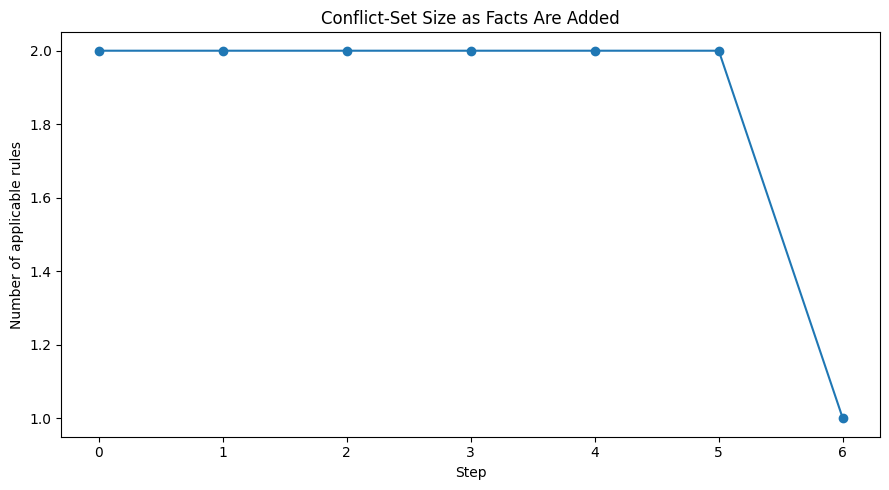

In [8]:

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(history_df["Step"],history_df["Conflict Set Size"],marker="o")
ax.set_title("Conflict-Set Size as Facts Are Added")
ax.set_xlabel("Step")
ax.set_ylabel("Number of applicable rules")
ax.set_xticks(history_df["Step"])
plt.tight_layout(); plt.show()


# 9. Plot — Working Memory Growth

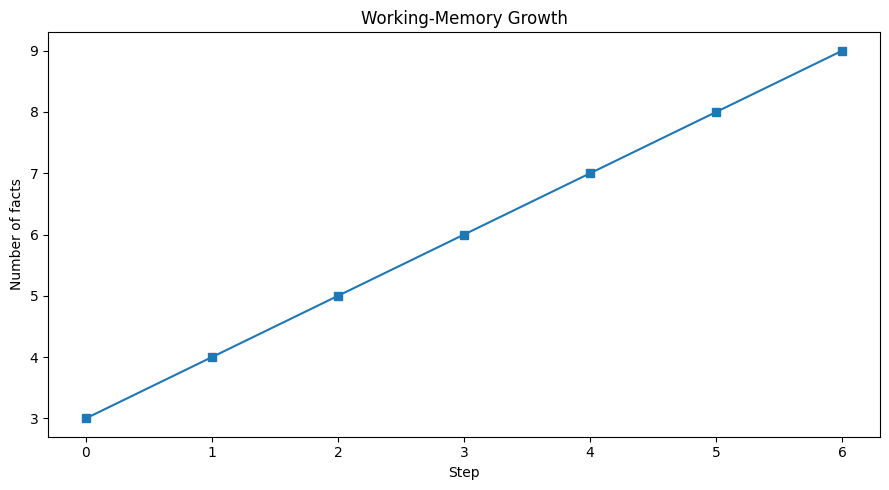

In [9]:

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(history_df["Step"],history_df["WM Size"],marker="s")
ax.set_title("Working-Memory Growth")
ax.set_xlabel("Step")
ax.set_ylabel("Number of facts")
ax.set_xticks(history_df["Step"])
plt.tight_layout(); plt.show()


# 10. Plot - Rule Applicability Heatmap

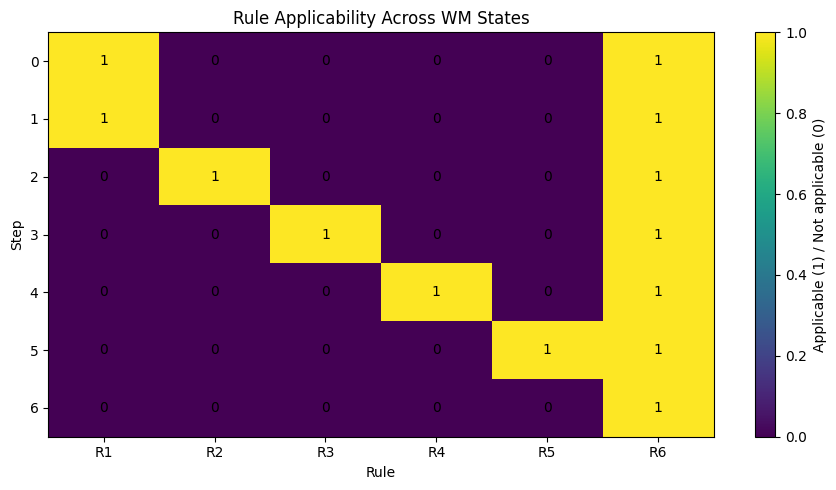

In [10]:

A=[]
for step in history_df["Step"]:
    wm=set(INITIAL_WM)
    if step>0: wm.update(FACT_ADDITIONS[:int(step)])
    ids={r.rule_id for r in conflict_set(RULES,wm)}
    A.append([int(r.rule_id in ids) for r in RULES])
A=np.array(A)

fig,ax=plt.subplots(figsize=(9,5))
im=ax.imshow(A,aspect="auto",interpolation="nearest")
ax.set_title("Rule Applicability Across WM States")
ax.set_xlabel("Rule"); ax.set_ylabel("Step")
ax.set_xticks(range(len(RULES))); ax.set_xticklabels([r.rule_id for r in RULES])
ax.set_yticks(range(len(history_df))); ax.set_yticklabels(history_df["Step"])
for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        ax.text(j,i,str(A[i,j]),ha="center",va="center")
plt.colorbar(im,ax=ax,label="Applicable (1) / Not applicable (0)")
plt.tight_layout(); plt.show()



# 11. Refractoriness Demonstration

A rule can have all its IF conditions satisfied but still be excluded because its conclusion is already in WM.

For R1:
- conditions: `has_key` and `door_closed`;
- conclusion: `can_open`.

If `can_open` is already in WM, R1 is not applicable.


In [11]:

wm_ref={"has_key","door_closed","safe","can_open"}
display(match_trace(RULES,wm_ref))
print("R1 applicable:", rule_matches(RULES[0],wm_ref))


,Rule,Conditions,All conditions satisfied,Conclusion,Conclusion absent,Applicable
0,R1,has_key AND door_closed,True,can_open,False,False
1,R2,can_open,True,door_open,True,True
2,R3,door_open,False,inside_room,True,False
3,R4,inside_room AND has_light,False,can_read,True,False
4,R5,can_read,False,reading,True,False
5,R6,door_closed AND safe,True,ready,True,True


R1 applicable: False



# 12. Exercise 2 - Negated Conditions (`NOT fact`)

A condition `NOT fact` is satisfied when `fact` is absent from WM.

Example:
`R7: IF NOT door_open AND has_key THEN waiting`

The refractoriness requirement remains unchanged.


In [12]:

def condition_satisfied(condition, wm):
    wm=set(wm)
    condition=condition.strip()
    if condition.startswith("NOT "):
        fact=condition[4:].strip()
        if not fact: raise ValueError("NOT must be followed by a fact.")
        return fact not in wm
    return condition in wm

def rule_matches_negation(rule, wm):
    wm=set(wm)
    return all(condition_satisfied(c,wm) for c in rule.conditions) and rule.conclusion not in wm

def conflict_set_negation(rules,wm):
    return [r for r in rules if rule_matches_negation(r,wm)]

NEGATED_RULES=RULES+[
    make_rule("R7",["NOT door_open","has_key"],"waiting"),
    make_rule("R8",["NOT has_light","safe"],"dark_room"),
    make_rule("R9",["NOT emergency","safe"],"normal_operation"),
]

for r in NEGATED_RULES:
    print(r)


R1: IF has_key AND door_closed THEN can_open
R2: IF can_open THEN door_open
R3: IF door_open THEN inside_room
R4: IF inside_room AND has_light THEN can_read
R5: IF can_read THEN reading
R6: IF door_closed AND safe THEN ready
R7: IF NOT door_open AND has_key THEN waiting
R8: IF NOT has_light AND safe THEN dark_room
R9: IF NOT emergency AND safe THEN normal_operation


In [13]:

wm_without={"has_key","door_closed","safe"}
wm_with={"has_key","door_closed","safe","door_open"}

print("Without door_open:",[r.rule_id for r in conflict_set_negation(NEGATED_RULES,wm_without)])
print("With door_open:",[r.rule_id for r in conflict_set_negation(NEGATED_RULES,wm_with)])


Without door_open: ['R1', 'R6', 'R7', 'R8', 'R9']
With door_open: ['R1', 'R3', 'R6', 'R8', 'R9']


In [14]:

def negation_trace(rules,wm):
    wm=set(wm); rows=[]
    for r in rules:
        results=[condition_satisfied(c,wm) for c in r.conditions]
        rows.append({
            "Rule":r.rule_id,
            "Conditions":" AND ".join(r.conditions),
            "Condition results":str(results),
            "All conditions":all(results),
            "Conclusion absent":r.conclusion not in wm,
            "Applicable":rule_matches_negation(r,wm)
        })
    return pd.DataFrame(rows)

display(negation_trace(NEGATED_RULES,wm_without))


,Rule,Conditions,Condition results,All conditions,Conclusion absent,Applicable
0,R1,has_key AND door_closed,"[True, True]",True,True,True
1,R2,can_open,[False],False,True,False
2,R3,door_open,[False],False,True,False
3,R4,inside_room AND has_light,"[False, False]",False,True,False
4,R5,can_read,[False],False,True,False
5,R6,door_closed AND safe,"[True, True]",True,True,True
6,R7,NOT door_open AND has_key,"[True, True]",True,True,True
7,R8,NOT has_light AND safe,"[True, True]",True,True,True
8,R9,NOT emergency AND safe,"[True, True]",True,True,True


# 13. Plot - Negated Rule Behaviour

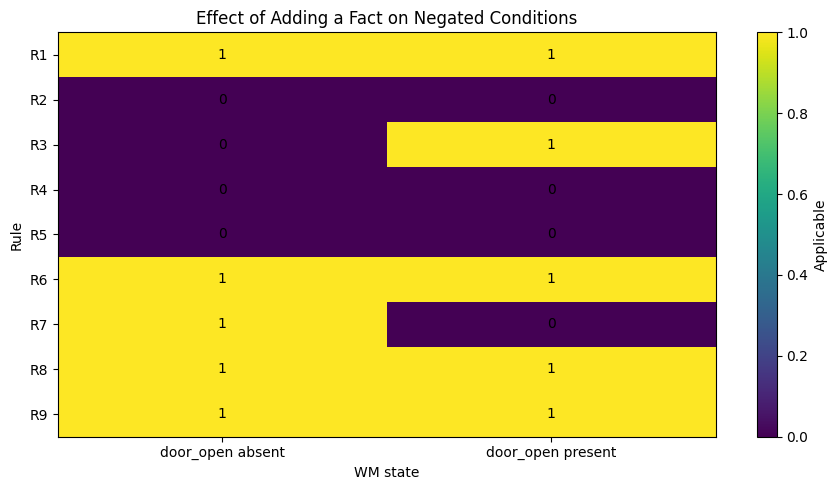

In [15]:

states=[("door_open absent",wm_without),("door_open present",wm_with)]
rows=[]
for label,wm0 in states:
    for r in NEGATED_RULES:
        rows.append({"State":label,"Rule":r.rule_id,
                     "Applicable":int(rule_matches_negation(r,wm0))})
p=pd.DataFrame(rows).pivot(index="Rule",columns="State",values="Applicable")

fig,ax=plt.subplots(figsize=(9,5))
im=ax.imshow(p.values,aspect="auto",interpolation="nearest")
ax.set_title("Effect of Adding a Fact on Negated Conditions")
ax.set_xlabel("WM state"); ax.set_ylabel("Rule")
ax.set_xticks(range(len(p.columns))); ax.set_xticklabels(p.columns)
ax.set_yticks(range(len(p.index))); ax.set_yticklabels(p.index)
for i in range(p.shape[0]):
    for j in range(p.shape[1]):
        ax.text(j,i,str(p.iloc[i,j]),ha="center",va="center")
plt.colorbar(im,ax=ax,label="Applicable")
plt.tight_layout(); plt.show()



# 14. Exercise 3 — Timing up to 1,000 Rules

The assignment specifically requests `time.perf_counter`.

For a straightforward scan of \(R\) rules with \(C\) conditions each, the match phase is approximately:

\[
O(RC)
\]

per full cycle.

We generate rules automatically and measure repeated runs. Exact times are machine-dependent; the trend is the important observation.


In [16]:

def generate_rules(n_rules, conditions_per_rule=2):
    return [
        Rule(
            rule_id=f"AUTO_{i+1}",
            conditions=tuple(f"fact_{i}_{j}" for j in range(conditions_per_rule)),
            conclusion=f"conclusion_{i}"
        )
        for i in range(n_rules)
    ]

def benchmark_match(n_rules,repeats=30,conditions_per_rule=2):
    rules=generate_rules(n_rules,conditions_per_rule)
    wm=set()
    times=[]
    for _ in range(repeats):
        t0=time.perf_counter()
        conflict_set(rules,wm)
        times.append(time.perf_counter()-t0)
    return {
        "Rules":n_rules,
        "Conditions/Rule":conditions_per_rule,
        "Median ms":np.median(times)*1000,
        "Mean ms":np.mean(times)*1000,
        "Min ms":np.min(times)*1000,
        "Max ms":np.max(times)*1000
    }

sizes=[10,50,100,250,500,750,1000]
benchmark_df=pd.DataFrame([benchmark_match(n) for n in sizes])
display(benchmark_df.style.format({
    "Median ms":"{:.5f}","Mean ms":"{:.5f}","Min ms":"{:.5f}","Max ms":"{:.5f}"
}))


,Rules,Conditions/Rule,Median ms,Mean ms,Min ms,Max ms
0,10,2,0.00965,0.01375,0.00470,0.08960
1,50,2,0.02270,0.02829,0.02190,0.18520
2,100,2,0.04560,0.04742,0.04470,0.08380
3,250,2,0.11250,0.12712,0.11010,0.19620
4,500,2,0.22580,0.23370,0.22100,0.32250
5,750,2,0.35490,0.38329,0.33620,0.55770
6,1000,2,0.45475,0.50331,0.43760,0.87860


# 15. Plot — Match Time vs Rule Count

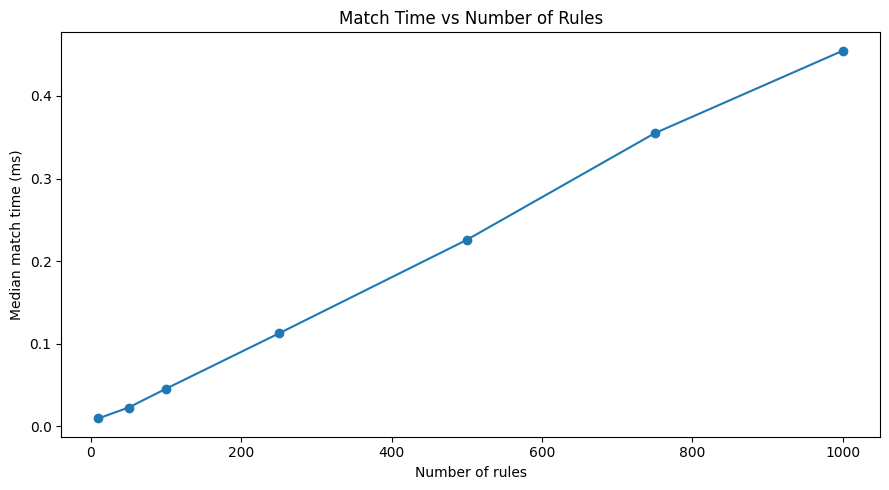

In [17]:

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(benchmark_df["Rules"],benchmark_df["Median ms"],marker="o")
ax.set_title("Match Time vs Number of Rules")
ax.set_xlabel("Number of rules")
ax.set_ylabel("Median match time (ms)")
plt.tight_layout(); plt.show()


# 16. Plot — Log-Log Scaling

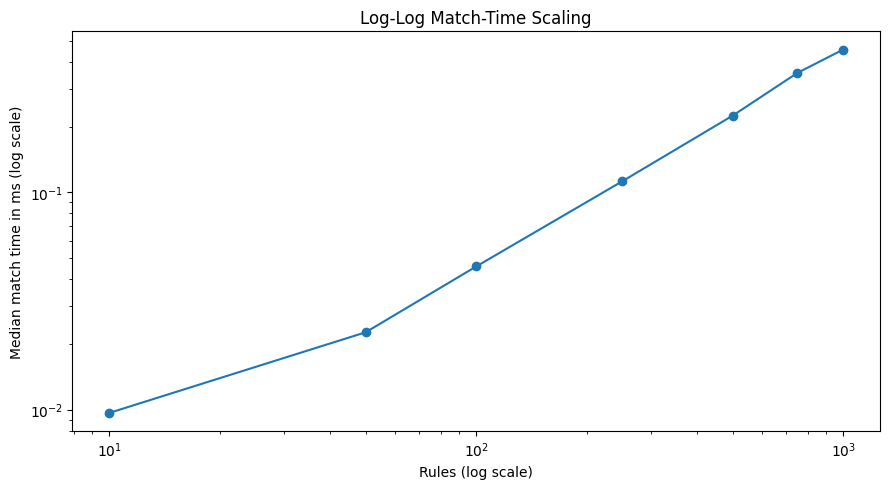

In [18]:

fig,ax=plt.subplots(figsize=(9,5))
ax.loglog(benchmark_df["Rules"],benchmark_df["Median ms"],marker="o")
ax.set_title("Log-Log Match-Time Scaling")
ax.set_xlabel("Rules (log scale)")
ax.set_ylabel("Median match time in ms (log scale)")
plt.tight_layout(); plt.show()


# 17. Plot — Mean and Maximum Time

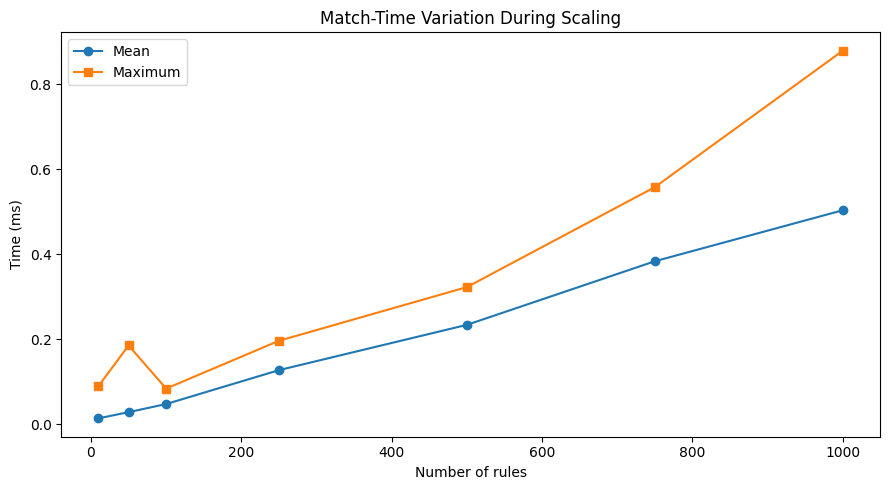

In [19]:

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(benchmark_df["Rules"],benchmark_df["Mean ms"],marker="o",label="Mean")
ax.plot(benchmark_df["Rules"],benchmark_df["Max ms"],marker="s",label="Maximum")
ax.set_title("Match-Time Variation During Scaling")
ax.set_xlabel("Number of rules")
ax.set_ylabel("Time (ms)")
ax.legend()
plt.tight_layout(); plt.show()



# 18. Additional Scaling Experiment — Conditions per Rule

The same 1,000-rule matcher is evaluated with 1–5 conditions per rule. This illustrates the \(O(RC)\) dependence of the straightforward matcher.


In [20]:

condition_df=pd.DataFrame([
    benchmark_match(1000,repeats=30,conditions_per_rule=c)
    for c in [1,2,3,4,5]
])
display(condition_df.style.format({
    "Median ms":"{:.5f}","Mean ms":"{:.5f}","Min ms":"{:.5f}","Max ms":"{:.5f}"
}))


,Rules,Conditions/Rule,Median ms,Mean ms,Min ms,Max ms
0,1000,1,0.51125,0.58105,0.44670,0.95000
1,1000,2,0.49635,0.53984,0.45700,0.78930
2,1000,3,0.47730,0.55104,0.45880,0.84120
3,1000,4,0.47310,0.49972,0.45900,0.97160
4,1000,5,0.47105,0.54456,0.45890,0.78770


# 19. Plot — Match Time vs Conditions per Rule

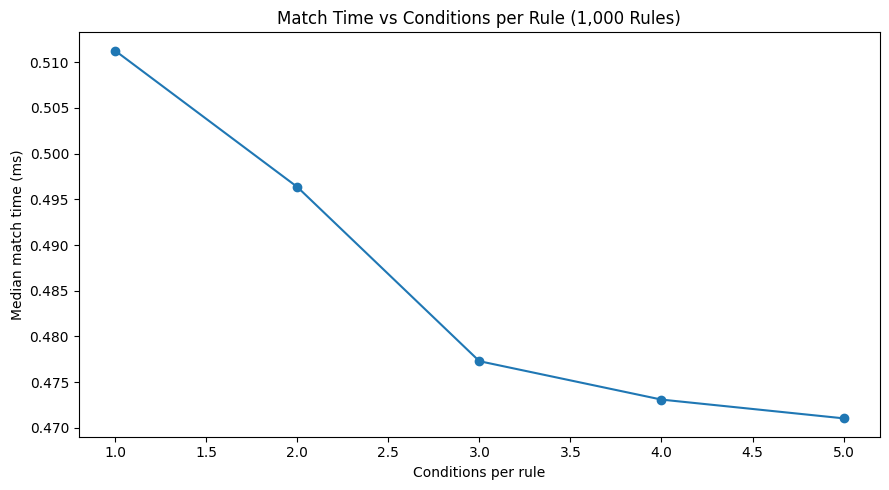

In [21]:

fig,ax=plt.subplots(figsize=(9,5))
ax.plot(condition_df["Conditions/Rule"],condition_df["Median ms"],marker="o")
ax.set_title("Match Time vs Conditions per Rule (1,000 Rules)")
ax.set_xlabel("Conditions per rule")
ax.set_ylabel("Median match time (ms)")
plt.tight_layout(); plt.show()



# 20. Why RETE Exists

The naive matcher repeatedly scans the rule base and checks conditions from scratch.

RETE-style production matching instead maintains an incremental network of partial matches. When WM changes, the system propagates the change through relevant parts of the network rather than recomputing every rule-condition combination.

Therefore:

- **Naive matching:** simple, transparent, but repeated full scans.
- **RETE:** more complex data structure, but reuses prior match information and is intended to reduce redundant work in large, changing production systems.

The benchmark measures this notebook's Python implementation, so absolute timing values are hardware/runtime dependent.



# 21. Observations

1. The conflict set contains exactly the rules whose conditions are satisfied and whose conclusions are absent from WM.
2. Adding facts can enable new rules and therefore change the conflict set.
3. Refractoriness removes a rule when its conclusion is already in WM.
4. `NOT fact` is satisfied when the fact is absent; adding that fact can invalidate a rule.
5. Full-scan matching becomes more expensive as the number of rules grows.
6. More conditions per rule increase matching work.
7. RETE addresses repeated matching by incrementally maintaining relevant partial matches.
8. This experiment stops at conflict-set construction; it does not perform conflict resolution or action execution.
